<a href="https://colab.research.google.com/github/kulanigayathree/J26-IT-364/blob/model%2FOil-Spill-Detection/notebooks/oil-spill/C4_03_features.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# C4 – Step 4: Build the features table
**What it does:** processes all images (~3,650), computes **numbers (features)** for every dark patch and builds a **table**. The next step **trains the 3 models** on this table.

⏳ The whole notebook takes about **10–15 minutes**. Use **Runtime → Run all** and wait.

## 1. Connect Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 2. Load the dataset and `c4_utils`
`c4_utils.py` was saved to Drive by C4_02.

In [ ]:
import os, sys, importlib, pandas as pd, numpy as np
DRIVE_DIR = '/content/drive/MyDrive/C4_OilSpill'
DATA_DIR  = f'{DRIVE_DIR}/data'
RES_DIR   = f'{DRIVE_DIR}/results'
LOCAL_DIR = '/content/DARTIS'
IMG_DIR   = f'{LOCAL_DIR}/files'
os.makedirs(IMG_DIR, exist_ok=True); os.makedirs(RES_DIR, exist_ok=True)

if len(os.listdir(IMG_DIR)) == 0:
    !tar -xf "{DATA_DIR}/DARTIS_2019_files.tar" -C "{LOCAL_DIR}"
print('Files:', len(os.listdir(IMG_DIR)))

assert os.path.exists(f'{DRIVE_DIR}/c4_utils.py'), 'c4_utils.py not found! Run the C4_02 notebook first.'
df = pd.read_csv(f'{DATA_DIR}/DARTIS_2019_metadata.csv')
df = df[df['jpg_file'].apply(lambda n: os.path.exists(f'{IMG_DIR}/{n}'))]
print('Images:', df.jpg_file.nunique())

Files: 5020
Images: 3655


## 3. Save the feature-extraction code
This code is saved to Drive as **`c4_features.py`** (also used by the training and frontend notebooks).

| Group | Features | Meaning |
|---|---|---|
| **Shape** | `area`, `perimeter`, `elongation`, `eccentricity`, `solidity`, `extent`, `compactness` | Size, length, shape |
| **Darkness** | `mean_int`, `std_int`, `min_int` | How dark the patch is |
| **Context** | `bg_mean`, `bg_std`, `contrast`, `intensity_ratio` | How much darker than the surrounding sea |
| **Edge** | `edge_gradient` | How sharp the boundary is |
| **Image** | `area_frac`, `img_mean`, `img_std`, `is_coast` | Whole-image conditions, coastal or not |

In [ ]:
%%writefile /content/drive/MyDrive/C4_OilSpill/c4_features.py
# c4_features.py  –  C4 Oil Spill Detection: patch feature extraction
# (Saved to Drive by the C4_03 notebook and imported by the training and frontend notebooks.)
import numpy as np
import cv2
import c4_utils as u

RING = 15   # width (pixels) of the surrounding-sea ring

FEATURES = [
    'area', 'perimeter', 'elongation', 'eccentricity', 'solidity', 'extent', 'compactness',
    'mean_int', 'std_int', 'min_int', 'bg_mean', 'bg_std', 'contrast', 'intensity_ratio',
    'edge_gradient', 'area_frac', 'img_mean', 'img_std', 'is_coast',
]


def patch_features(res, is_coast=0):
    """
    Return a feature dict for every patch in a u.detect() result.
      Shape     : area, perimeter, elongation, eccentricity, solidity, extent, compactness
      Darkness  : mean_int, std_int, min_int
      Context   : bg_mean, bg_std, contrast, intensity_ratio (patch vs surrounding sea)
      Edge      : edge_gradient (how sharp the boundary is)
      Image     : area_frac, img_mean, img_std, is_coast
    """
    f = res['filtered'].astype(np.float32)
    labels = res['labels']
    H, W = f.shape
    valid = f > 0
    img_mean = float(f[valid].mean()) if valid.any() else 0.0
    img_std = float(f[valid].std()) if valid.any() else 0.0
    gx = cv2.Sobel(f, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(f, cv2.CV_32F, 0, 1, ksize=3)
    grad = np.sqrt(gx ** 2 + gy ** 2)
    k_ring = np.ones((2 * RING + 1, 2 * RING + 1), np.uint8)
    k3 = np.ones((3, 3), np.uint8)

    rows = []
    for p in res['props']:
        r0, c0, r1, c1 = p.bbox
        R0, C0 = max(r0 - RING, 0), max(c0 - RING, 0)
        R1, C1 = min(r1 + RING, H), min(c1 + RING, W)
        lab = labels[R0:R1, C0:C1]
        fc, gc, vc = f[R0:R1, C0:C1], grad[R0:R1, C0:C1], valid[R0:R1, C0:C1]
        mask = (lab == p.label).astype(np.uint8)

        ring = (cv2.dilate(mask, k_ring) > 0) & (lab == 0) & vc
        bg = fc[ring]
        bg_mean = float(bg.mean()) if bg.size else img_mean
        bg_std = float(bg.std()) if bg.size else img_std

        inside = fc[mask > 0]
        mean_int = float(inside.mean())
        boundary = (mask > 0) & ~(cv2.erode(mask, k3) > 0)
        edge = float(gc[boundary].mean()) if boundary.any() else 0.0

        major = float(getattr(p, 'axis_major_length', None) or p.major_axis_length)
        minor = float(getattr(p, 'axis_minor_length', None) or p.minor_axis_length)
        perim = float(p.perimeter) if p.perimeter > 0 else 1.0
        rows.append(dict(
            area=float(p.area),
            perimeter=perim,
            elongation=major / max(minor, 1.0),
            eccentricity=float(p.eccentricity),
            solidity=float(p.solidity),
            extent=float(p.extent),
            compactness=float(4 * np.pi * p.area / perim ** 2),
            mean_int=mean_int,
            std_int=float(inside.std()),
            min_int=float(inside.min()),
            bg_mean=bg_mean,
            bg_std=bg_std,
            contrast=(bg_mean - mean_int) / max(bg_mean, 1.0),
            intensity_ratio=mean_int / max(bg_mean, 1.0),
            edge_gradient=edge / max(bg_mean, 1.0),
            area_frac=float(p.area) / (H * W),
            img_mean=img_mean,
            img_std=img_std,
            is_coast=int(is_coast),
        ))
    return rows


def image_features(path, boxes=None, is_oil_image=False, is_coast=0):
    """Image -> patches -> features + labels (for training)."""
    res = u.detect(path)
    feats = patch_features(res, is_coast)
    labs = u.label_patches(res['props'], boxes or [], is_oil_image)
    for row, lab, p in zip(feats, labs, res['props']):
        row['label'] = lab
        row['centroid_r'], row['centroid_c'] = (float(v) for v in p.centroid)
    return feats


Writing /content/drive/MyDrive/C4_OilSpill/c4_features.py


In [ ]:
sys.path.insert(0, DRIVE_DIR)
import c4_utils as u, c4_features as cf
importlib.reload(u); importlib.reload(cf)
print('Features:', len(cf.FEATURES), '✅')

Features: 19 ✅


## 4. Process all images ⏳ (8–12 minutes)
Uses all Colab CPU cores. Watch the progress bar.

In [ ]:
from joblib import Parallel, delayed
from tqdm.auto import tqdm

jobs = []
for name, g in df.groupby('jpg_file'):
    is_oil = bool(g.is_oil.iloc[0])
    boxes = list(zip(g.obj_patchloc_xmin, g.obj_patchloc_ymin, g.obj_patchloc_xmax, g.obj_patchloc_ymax)) if is_oil else []
    jobs.append(dict(name=name, subset=g.subset.iloc[0], start_time=g.start_time.iloc[0],
                     boxes=boxes, is_oil=is_oil, is_coast=int(g.subset.iloc[0] in ('oc', 'nc'))))

def run(job, drive_dir, img_dir):
    import sys
    if drive_dir not in sys.path:
        sys.path.insert(0, drive_dir)
    import c4_features as cfw          # each CPU worker imports its own copy
    try:
        rows = cfw.image_features(f"{img_dir}/{job['name']}", job['boxes'], job['is_oil'], job['is_coast'])
    except Exception:
        return []
    for r in rows:
        r.update(image=job['name'], subset=job['subset'], start_time=job['start_time'])
    return rows

all_rows, CHUNK = [], 64
with Parallel(n_jobs=-1) as par:
    for i in tqdm(range(0, len(jobs), CHUNK), desc='Images (x64)'):
        for rows in par(delayed(run)(j, DRIVE_DIR, IMG_DIR) for j in jobs[i:i+CHUNK]):
            all_rows.extend(rows)

feat = pd.DataFrame(all_rows)
print('Total patches:', len(feat))
print(feat.label.value_counts())

Images (x64):   0%|          | 0/58 [00:00<?, ?it/s]

Total patches: 36523
label
look-alike    27225
oil            4759
ignore         4539
Name: count, dtype: int64


## 5. Clean up and save
- Remove **`ignore`** patches (patches in oil images outside the oil boxes; uncertain)
- **Train / test split (80% / 20%)**: all images from the same **satellite pass** (`start_time`) go to the same side, so the model is never tested on images it has seen. This keeps the results fair.

In [ ]:
from sklearn.model_selection import GroupShuffleSplit

data = feat[feat.label != 'ignore'].reset_index(drop=True)
data['y'] = (data.label == 'oil').astype(int)

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(data, data.y, groups=data.start_time))
data['split'] = 'train'
data.loc[test_idx, 'split'] = 'test'

data.to_csv(f'{DATA_DIR}/features.csv', index=False)
print('Saved ✅', f'{DATA_DIR}/features.csv')
print(pd.crosstab(data.label, data.split, margins=True))

Saved ✅ /content/drive/MyDrive/C4_OilSpill/data/features.csv
split       test  train    All
label                         
look-alike  5062  22163  27225
oil          621   4138   4759
All         5683  26301  31984


## 6. Oil vs look-alike: feature differences 📊
Each box shows the middle 50% of patches. If the two boxes sit at **different levels**, that feature is **useful** for separating oil from look-alikes.

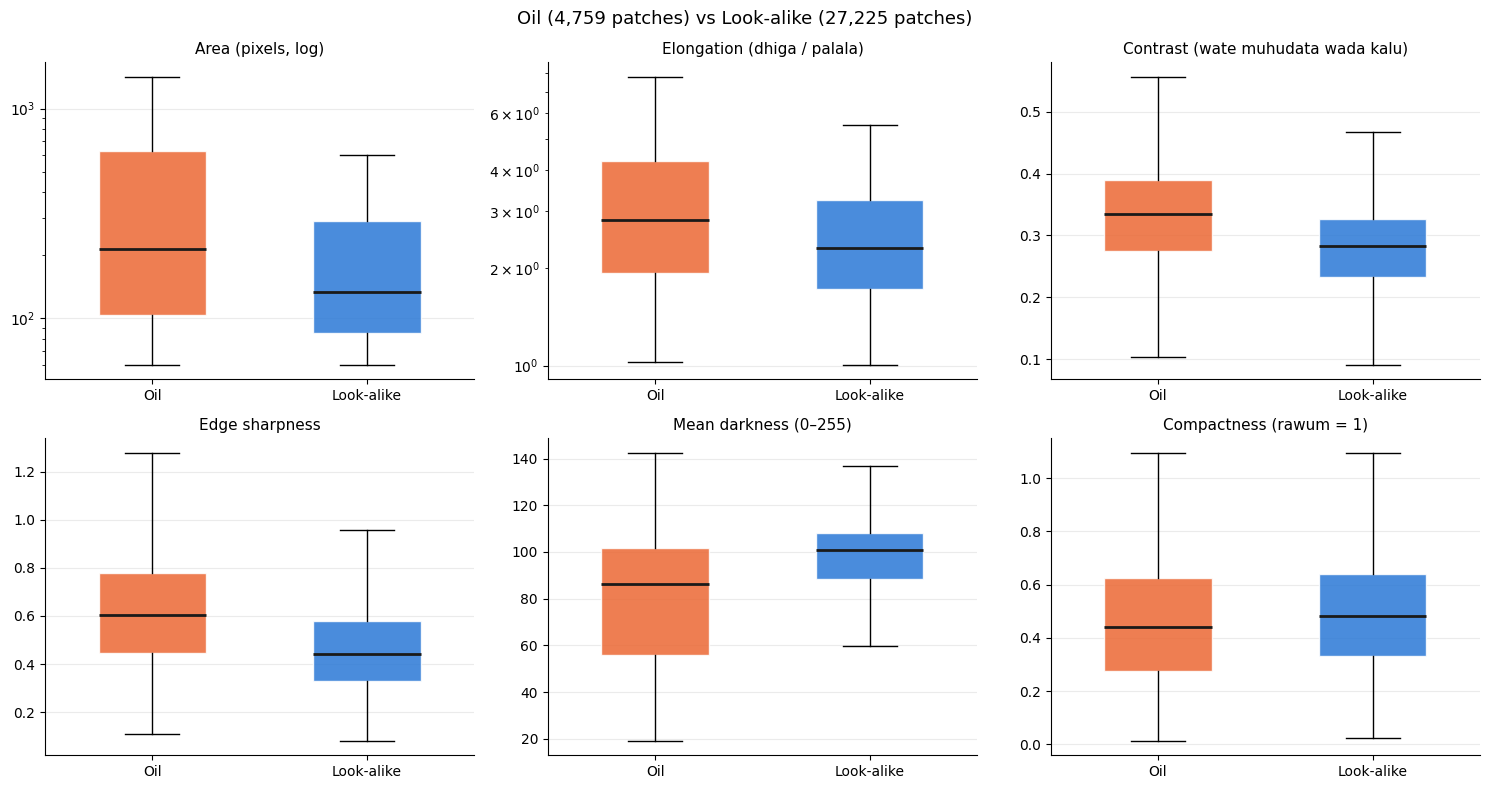

In [ ]:
import matplotlib.pyplot as plt

COLORS = {'Oil': '#eb6834', 'Look-alike': '#2a78d6'}
SHOW = [('area', 'Area (pixels, log)', True), ('elongation', 'Elongation (length / width)', True),
        ('contrast', 'Contrast (darker than surrounding sea)', False), ('edge_gradient', 'Edge sharpness', False),
        ('mean_int', 'Mean darkness (0–255)', False), ('compactness', 'Compactness (circle = 1)', False)]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, (col, title, logy) in zip(axes.ravel(), SHOW):
    vals = [data.loc[data.y == 1, col], data.loc[data.y == 0, col]]
    bp = ax.boxplot(vals, showfliers=False, patch_artist=True, widths=0.5,
                    medianprops=dict(color='#1a1a19', lw=2))
    for patch, c in zip(bp['boxes'], COLORS.values()):
        patch.set_facecolor(c); patch.set_alpha(0.85); patch.set_edgecolor('white')
    ax.set_xticks([1, 2]); ax.set_xticklabels(['Oil', 'Look-alike'])
    ax.set_title(title, fontsize=11)
    if logy: ax.set_yscale('log')
    ax.grid(axis='y', alpha=0.25); ax.spines[['top', 'right']].set_visible(False)
fig.suptitle(f"Oil ({(data.y==1).sum():,} patches) vs Look-alike ({(data.y==0).sum():,} patches)", fontsize=13)
plt.tight_layout()
plt.savefig(f'{RES_DIR}/03_features.png', dpi=120)
plt.show()

## 7. Summary table (median values)

In [ ]:
summary = data.groupby('label')[cf.FEATURES].median().T.round(3)
summary

label,look-alike,oil
area,134.000,214.000
perimeter,59.142,78.971
elongation,2.304,2.819
eccentricity,0.901,0.935
solidity,0.754,0.767
extent,0.511,0.479
compactness,0.481,0.440
mean_int,100.884,86.141
std_int,6.006,7.564
min_int,84.000,57.000


## ✅ Done!
- `data/features.csv` → used to **train the 3 models** in the next step
- `results/03_features.png` → for the PP1 **feature extraction** slide

**🔔 COMMIT:** File → Save a copy in GitHub → `notebooks/oil-spill/C4_03_features.ipynb` → `feat(oil-spill): extract patch features and create train/test split`